# LG · Де рубатимуть наступного року?

**Тип:** виміряно. **Навіщо:** Перевіряємо, чи можна передбачити рубки в парку, де вони рідкісні.

Цей ноутбук повторює блок сторінки досліджень `web/science/#lg` і бере ті самі результати.

In [1]:
import sys
sys.path.insert(0, '..')
import pandas as pd
from eaglewings.ds import report
pd.set_option('display.width', 200)
%matplotlib inline

## Постановка, дані, протокол і метрики

Текст узято з модуля задачі, той самий записується в журнал кожного запуску.

In [2]:
print(report.protocol('LG'))

LD · LM · LG для Греції: детекція, матчинг і розвиток вирубки в НП Дадья.

Задача      перевірити вирубку на грецькому парку й чесно показати, що можна виміряти там, де рубок мало.
Дані        Sentinel-2 L2A (AWS Earth Search): літні композити 15.06–15.09; NASA OPERA DIST-ALERT через GIBS; Hansen GFC v1.12 як лейбл; рельєф SRTM, ліс, дороги й села.
Лейбл       Hansen: втрата крон саме в році Y. Це не «рубка», а будь-яка втрата лісу.
Пожежі      це не вирубка, тому пікселі ≤ 1 км від точок FIRMS (є лише з 2021) і в контурах EFFIS + 500 м за роки Y і Y−1 відкинуті. Лишкові згарища все одно можливі.
Протокол    кілька парків: квадрати ~6 км усіх парків розкладені на фолди (вибір і тест на різних квадратах); окремо LD_transfer і LM_transfer —
            вчимося на інших парках, тест на парку, якого модель не бачила (не для вибору). З одним парком — половини парку за довготою.
  LD        вибір 2018–2021, тест 2022–2024. CI — bootstrap по блоках ~5 км.
  LM        Sentinel-2 навчається на 

## Результат

Обраний підхід виділено. Вибір робився лише на валідації, числа тут з тесту.

,approach,val_metric,test_metric,ci,precision,recall,true_ha,champion,diff_hist,diff_rand
0,випадково,0.172,0.059,0.02–0.16,NaN,NaN,59.613,False,-0.181,0.000
1,де рубали торік,0.271,0.240,0.12–0.36,NaN,NaN,59.613,False,0.000,0.181
2,близькість,0.307,0.139,0.08–0.21,NaN,NaN,59.613,False,-0.101,0.080
3,логрег,0.569,0.513,0.28–0.84,NaN,NaN,59.613,True,0.273,0.454
4,LightGBM,0.511,0.810,0.52–0.93,NaN,NaN,59.613,False,0.570,0.751


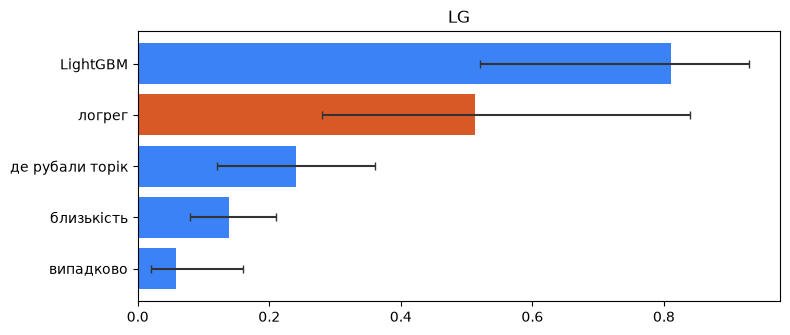

In [3]:
table, fig = report.show('LG')
table

## По роках

Прогресивний протокол: кожен рік бачить лише дані до нього.

In [4]:
report.by_year('LG')

approach,LightGBM,близькість,випадково,де рубали торік,логрег
year,,,,,
2018.0,0.447,0.264,0.202,0.258,0.595
2019.0,0.636,0.339,0.087,0.275,0.513
2020.0,0.721,0.555,0.125,0.351,0.498
2021.0,0.884,0.132,0.017,0.234,0.582
2022.0,0.635,0.139,0.168,0.212,0.569
2023.0,0.806,0.151,0.000,0.194,0.295
2024.0,0.576,0.172,0.263,0.384,0.293


## Частка втрат залежно від площі

In [5]:
report.results('t19', 'LG_curve').pivot_table(index='approach', columns='share', values='test_metric').round(3)

share,0.02,0.05,0.11,0.20,0.30,0.50
approach,,,,,,
LightGBM,0.112,0.361,0.810,0.932,0.967,0.996
близькість,0.077,0.125,0.139,0.207,0.274,0.448
випадково,0.001,0.011,0.059,0.240,0.319,0.461
де рубали торік,0.098,0.186,0.240,0.311,0.403,0.565
логрег,0.106,0.284,0.513,0.890,0.949,0.968
